# ECG Preprocessing with PTB-XL

This notebook allows to:
- access to the signals in the `/500` folder of the PTB-XL dataset,
- load files either locally or on demand,
- apply an example ECG preprocessing step,
- create a results file only when necessary.

> The goal is to avoid downloading or storing the whole dataset locally when it is not needed.

In [ ]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import wfdb

%matplotlib inline


def find_project_root(start=None, marker="CLAUDE.md"):
    """Walk upward from `start` (default: this notebook's cwd) until a
    directory containing `marker` is found. Makes path resolution work
    whether Jupyter's cwd is the notebook's own directory (the common case)
    or the project root, instead of assuming one or the other."""
    current = Path(start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"Could not locate project root (missing {marker}) from {current}")


PROJECT_ROOT = find_project_root()
print("Project root:", PROJECT_ROOT)
print("Environment ready")


## 1. Audit of the provided PTB-XL example

The original example uses a path variable and a function that loads ECG files from the dataset. The main issue is to make sure the path points to the correct local folder and to access records under the `/500` directory correctly.

In this notebook, the path is built from the downloaded dataset folder and the record names are read from the metadata file.

In [ ]:
base_dir = PROJECT_ROOT
dataset_dir = base_dir / 'kaggle' / 'archive' / 'ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3'
metadata_path = dataset_dir / 'ptbxl_database.csv'

print('Dataset directory:', dataset_dir)
print('Metadata file exists:', metadata_path.exists())


## 2. Two modes for loading files

You can choose between:
1. Local mode: download or use the already downloaded files from the dataset folder.
2. On-demand mode: load a file only when needed, without storing a large local copy.

The second mode is preferable when storage is limited.

In [3]:
def load_local_record(record_path):
    sig, meta = wfdb.rdsamp(record_path)
    return sig, meta


def load_on_demand_record(record_path):
    sig, meta = wfdb.rdsamp(record_path)
    return sig, meta

print('Loading helpers ready')

Loading helpers ready


## 3. List all available signals in the `/500` folder

The PTB-XL metadata file already contains the record names for the 500 Hz signals. We can use the `filename_hr` column for that purpose.

In [4]:
df = pd.read_csv(metadata_path)
records_500 = df['filename_hr'].dropna().tolist()
print('Number of 500 Hz records:', len(records_500))
print('First 10 records:')
records_500[:10]

Number of 500 Hz records: 21799
First 10 records:


['records500/00000/00001_hr',
 'records500/00000/00002_hr',
 'records500/00000/00003_hr',
 'records500/00000/00004_hr',
 'records500/00000/00005_hr',
 'records500/00000/00006_hr',
 'records500/00000/00007_hr',
 'records500/00000/00008_hr',
 'records500/00000/00009_hr',
 'records500/00000/00010_hr']

## 4. Lazy loading for a single record

This cell loads one record only when needed. It avoids keeping a large local copy of the whole dataset in memory.

In [5]:
example_record = records_500[0]
example_path = dataset_dir / example_record

sig_example, meta_example = wfdb.rdsamp(str(example_path))
print('Loaded record:', example_record)
print('Signal shape:', sig_example.shape)
print('Sampling rate:', meta_example['fs'])

Loaded record: records500/00000/00001_hr
Signal shape: (5000, 12)
Sampling rate: 500


## 7. Structured workflow using the Python module

The first part of this notebook keeps the exploratory example. This new section uses the reusable functions from the Python module so the workflow is easier to maintain and reuse.

In [ ]:
import sys
from pathlib import Path

src_dir = PROJECT_ROOT / 'src'
sys.path.insert(0, str(src_dir))

print('Source directory:', src_dir)

try:
    from ecg_preprocessing import ecg_preprocessing_pipeline, plot_pipeline
    print('Module imported successfully.')
    print('Available functions:', ecg_preprocessing_pipeline.__name__, plot_pipeline.__name__)
except Exception as exc:
    print('Import failed:', exc)
    raise


In [ ]:
base_dir = PROJECT_ROOT
dataset_dir = base_dir / 'kaggle' / 'archive' / 'ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3'
metadata_path = dataset_dir / 'ptbxl_database.csv'

df = pd.read_csv(metadata_path)
records_500 = df['filename_hr'].dropna().tolist()

print('Dataset directory:', dataset_dir)
print('Metadata file exists:', metadata_path.exists())
print('Number of 500 Hz records:', len(records_500))
print('First 5 records:', records_500[:5])


In [8]:
example_record = records_500[0]
example_path = dataset_dir / example_record

sig_example, meta_example = wfdb.rdsamp(str(example_path))
print('Loaded record:', example_record)
print('Signal shape:', sig_example.shape)
print('Sampling rate:', meta_example['fs'])

Loaded record: records500/00000/00001_hr
Signal shape: (5000, 12)
Sampling rate: 500


In [9]:
signal = sig_example[:, 0]
fs = meta_example['fs']

results = ecg_preprocessing_pipeline(signal, fs)
print('Number of detected R peaks:', len(results['r_peaks']))
print('First few R peaks:', results['r_peaks'][:10])

Number of detected R peaks: 11
First few R peaks: [  97  576 1037 1504 1968 2423 2912 3381 3866 4325]


In [10]:
record_name = Path(example_record).name
base_record_dir = base_dir / 'results' / 'records' / record_name
module_dir = base_record_dir / 'full_pipeline'

print('Ready to use module visualization for record:', record_name)
print('Output folder:', module_dir)

Ready to use module visualization for record: 00001_hr
Output folder: c:\Users\neifa\Documents\ENETCOM\3IDSD\stage_25-26\cardiac-multiagent-pipeline\results\records\00001_hr\full_pipeline


Figure saved to: c:\Users\neifa\Documents\ENETCOM\3IDSD\stage_25-26\cardiac-multiagent-pipeline\results\records\00001_hr\full_pipeline\00001_hr_full_pipeline.png


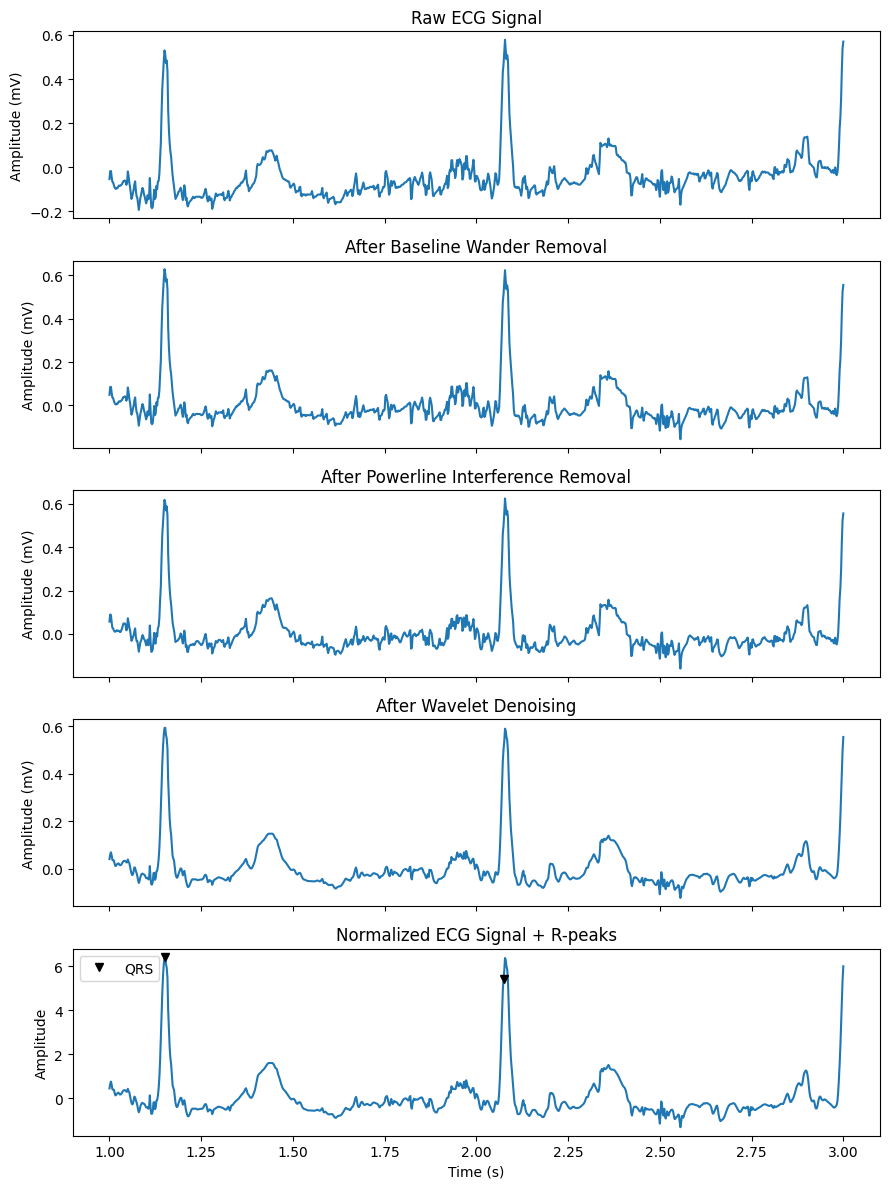

In [11]:
record_name = Path(example_record).name
base_record_dir = base_dir / 'results' / 'records' / record_name
module_dir = base_record_dir / 'full_pipeline'
module_dir.mkdir(parents=True, exist_ok=True)

save_results = True
if save_results:
    plot_pipeline(
        results,
        fs,
        t_start=1.0,
        t_end=3.0,
        output_dir=str(module_dir),
        file_name=f'{record_name}_full_pipeline',
    )
else:
    print('No file saved. Set save_results = True to create the multi-part module figure.')

In [ ]:
from ecg_agent import generate_ecg_contribution, save_contribution

# Uses the free local Ollama backend by default (no Anthropic key needed).
# Requires Ollama installed and running locally with a model pulled, e.g.:
#   ollama pull medgemma:4b
contribution = generate_ecg_contribution(
    results,
    fs,
    record_id=record_name,
    patient_info="Homme, 58 ans, douleur thoracique",
)
print(contribution)

output_path = save_contribution(contribution, output_dir=str(base_record_dir), file_name="ecg_contribution")
print("Saved to:", output_path)
